In [1]:
%pip install -q gwpy
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

Note: you may need to restart the kernel to use updated packages.


# Gravitational-Wave Polarization — Extended Kalman Filter (Jones Formalism)

A gravitational wave stretches and squeezes space in two independent patterns, its two
**polarizations**, written $h_+$ and $h_\times$. How the wave divides itself between them tells us
how the source is oriented, for example how the orbit of a pair of black holes is tilted toward
us.

Following Amblard and Michel, the two polarizations are written as one two-component complex
signal, a **Jones vector**:

$$
\mathbf{z}_t = a_t\,e^{i\psi_t}\begin{pmatrix}\cos(\theta_t/2) \\ \sin(\theta_t/2)\,e^{i\varphi_t}\end{pmatrix} + \boldsymbol{\epsilon}_t
$$

Here $a_t > 0$ is the amplitude, $\psi_t$ the phase of the carrier wave, $(\theta_t, \varphi_t)$
the two polarization angles and $\boldsymbol{\epsilon}_t$ the noise. The angles are the latitude
and longitude of a point on a sphere, the **Poincaré sphere**: each polarization state is one
point on it, and a source whose orientation changes draws a path.

An Extended Kalman Filter (EKF), the Kalman filter for nonlinear models, estimates $a$, $\psi$,
$\theta$ and $\varphi$ while they change.

The signals here are in toy units: amplitudes of order 1 and frequencies of a few Hz, sampled at
100 Hz. Real detectors record strains of order $10^{-21}$ between about 10 Hz and a few kHz. Once
the data are divided by the noise level, the same filter applies with a faster time axis.

The detector itself is the subject of `04_MechanicalSuspension.ipynb`.

## The Model and Key Terms

The state holds four quantities and the rate of change of each:

$$\mathbf{x}=[\ln a,\ v_a,\ \psi,\ v_\psi,\ \theta,\ v_\theta,\ \varphi,\ v_\varphi]^\top$$

- The filter tracks $\ln a$ rather than $a$, so that $a = e^{\ln a}$ stays positive. This also
  removes an ambiguity: $(a, \psi)$ and $(-a, \psi+\pi)$ give the same signal.
- $v_\psi = \dot\psi$ is the angular frequency of the carrier, so its frequency is
  $f = v_\psi/2\pi$.

Each quantity $q$ is assumed to change at a nearly constant rate $v_q$, disturbed by random
accelerations of strength $\sigma_q$:

$$\mathbf{F}=\mathrm{blkdiag}\begin{pmatrix}1&\Delta t\\0&1\end{pmatrix}_{\times4},\qquad
\mathbf{Q}_{\text{pair}}=\sigma_q^2\begin{pmatrix}\tau^3/3&\tau^2/2\\\tau^2/2&\tau\end{pmatrix}$$

$\Delta t = 1/f_s$ is the sample step. The noise uses a separate time $\tau$ (the argument
`delta`) in place of $\Delta t$. It sets how much each quantity may change from one sample to the
next, so it acts as the bandwidth of the filter: a larger $\tau$ follows faster changes but
averages away less noise.

The measurement is $\mathbf{z}=[\mathrm{Re}\,z_1,\ \mathrm{Im}\,z_1,\ \mathrm{Re}\,z_2,\
\mathrm{Im}\,z_2]^\top$, with noise covariance $\mathbf{R}=\sigma_n^2 \mathbf{I}_4$. It depends
nonlinearly on the state, so at each step the EKF uses its Jacobian
$\mathbf{H}=\partial h/\partial \mathbf{x}$.

In [2]:
from scipy.linalg import solve_discrete_are
from kalman.apps.gravitational.gravwave import PolarizationModel, jones_signal

## Step 1 — Build a Synthetic Signal

We first build a signal whose true parameters we know, so that the filter's errors can be
measured. Its carrier is a **chirp**, a tone whose frequency rises with time, as for two black
holes that spiral into each other. Here the frequency rises linearly from 1 Hz to 2 Hz in 40 s:

$$\psi_t = 2\pi\left(f_0\, t + \tfrac12 k\, t^2\right),\qquad f_0 = 1\ \text{Hz},\quad k = 0.025\ \text{Hz/s}$$
$$a_t = 1 + 0.1\cos(2\pi\cdot 0.2\,t),\qquad
\theta_t = \tfrac{\pi}{2}\bigl(1 + \tfrac12\sin(2\pi\cdot 0.05\,t)\bigr),\qquad
\varphi_t = \pi\bigl(1 + \tfrac12\sin(2\pi\cdot 0.1\,t + \xi)\bigr)$$

with $\xi$ a random phase and $t$ in s. The noise, $\sigma_n = 0.3$ on each real component, is
comparable with the signal. The cell prints the signal-to-noise ratio (SNR): the standard
deviation of the clean first component divided by $\sigma_n$.

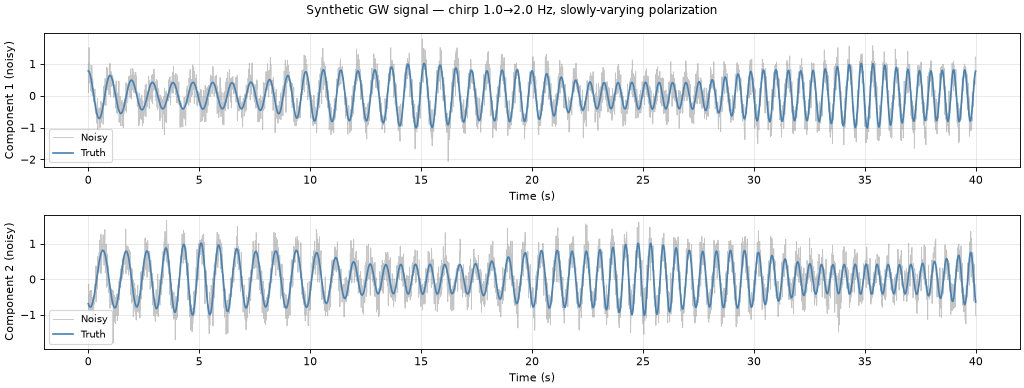

N=4000 | σ_n=0.3 | SNR ≈ 1.67
Chirp: 1.0 -> 2.0 Hz | d2psi/dt2 = 0.157 rad/s^2


In [3]:
fs  = 100.0     # sample rate [Hz]
T   = 40.0      # duration [s]
t   = np.arange(int(T * fs)) / fs

np.random.seed(0)
xi = np.random.uniform(0, 2 * np.pi)

# Amplitude: slow cosine oscillation
a_true     = 1.0 + 0.1 * np.cos(2 * np.pi * 0.2 * t)

# Carrier: chirp from 1 Hz to 2 Hz over T seconds
f0_chirp = 1.0
fT_chirp = 2.0
chirp_rate = (fT_chirp - f0_chirp) / T   # 0.025 Hz/s
psi_true   = 2 * np.pi * (f0_chirp * t + 0.5 * chirp_rate * t**2)

# Polarization: slowly-varying
theta_true = (np.pi / 2) * (1.0 + 0.5 * np.sin(2 * np.pi * 0.05 * t))
phi_true   = np.pi       * (1.0 + 0.5 * np.sin(2 * np.pi * 0.10 * t + xi))

# Build clean bivariate Jones signal
N = len(t)
z_clean = np.zeros((N, 2), dtype=complex)
for k in range(N):
    z_clean[k] = jones_signal(a_true[k], psi_true[k], theta_true[k], phi_true[k])

# Observation noise  (σ_n = 0.3 → SNR ≈ 1.7)
sigma_n = 0.3
noise = (np.random.normal(0, sigma_n, (N, 2))
       + 1j * np.random.normal(0, sigma_n, (N, 2)))
z_noisy = z_clean + noise

# Real 4-column measurement array
zk = np.column_stack([z_noisy[:, 0].real, z_noisy[:, 0].imag,
                      z_noisy[:, 1].real, z_noisy[:, 1].imag])

fig, axes = plt.subplots(2, 1, figsize=(13, 5))
for i, label in enumerate(['Component 1 (noisy)', 'Component 2 (noisy)']):
    axes[i].plot(t, z_noisy[:, i].real,  alpha=0.45, color='gray', lw=0.8, label='Noisy')
    axes[i].plot(t, z_clean[:, i].real,  color='steelblue',        lw=1.5, label='Truth')
    axes[i].set_xlabel('Time (s)')
    axes[i].set_ylabel(label)
    axes[i].legend(fontsize=9)
    axes[i].grid(True, alpha=0.3)

fig.suptitle(f'Synthetic GW signal — chirp {f0_chirp}→{fT_chirp} Hz, slowly-varying polarization', fontsize=11)
plt.tight_layout()
plt.show()

alpha_chirp = 2 * np.pi * chirp_rate   # d²ψ/dt² in rad/s²
print(f"N={N} | σ_n={sigma_n} | SNR ≈ {np.std(z_clean[:, 0].real)/sigma_n:.2f}")
print(f"Chirp: {f0_chirp} -> {fT_chirp} Hz | d2psi/dt2 = {alpha_chirp:.3f} rad/s^2")

## Step 2 — Run the EKF on the Synthetic Signal

| Parameter | Value | Meaning |
|---|---|---|
| `delta` ($\tau$) | 0.5 s | noise time, sets the bandwidth |
| `sigma_n` | 0.3 | measurement noise, a standard deviation |
| `sigma_a` | 0.05 s$^{-3/2}$ | how fast $\ln a$ may change |
| `sigma_psi` | 0.6 rad s$^{-3/2}$ | how fast the phase and the frequency may change |
| `sigma_theta`, `sigma_phi` | 0.05 rad s$^{-3/2}$ | how fast the polarization angles may change |

Following the phase of a chirp is what a **phase-locked loop** (PLL) does: a feedback loop that
keeps an oscillator in step with an incoming tone. The EKF behaves like a PLL with natural
frequency $\omega_n=\sqrt{\sigma_\psi^2\,\tau/\sigma_n^2}$. When the frequency rises, the loop lags
behind by about $\varepsilon = \ddot\psi/\omega_n^2$, and it stays locked if this lag is small,
say below 0.1 rad. The cell prints both numbers.

The filter starts with $\mathbf{P}_0$ equal to the covariance it would reach after a long run,
found pair by pair from the discrete algebraic Riccati equation (DARE). This avoids a long
start-up transient.

PLL: omega_n = 1.41 rad/s, lag = 0.079 rad


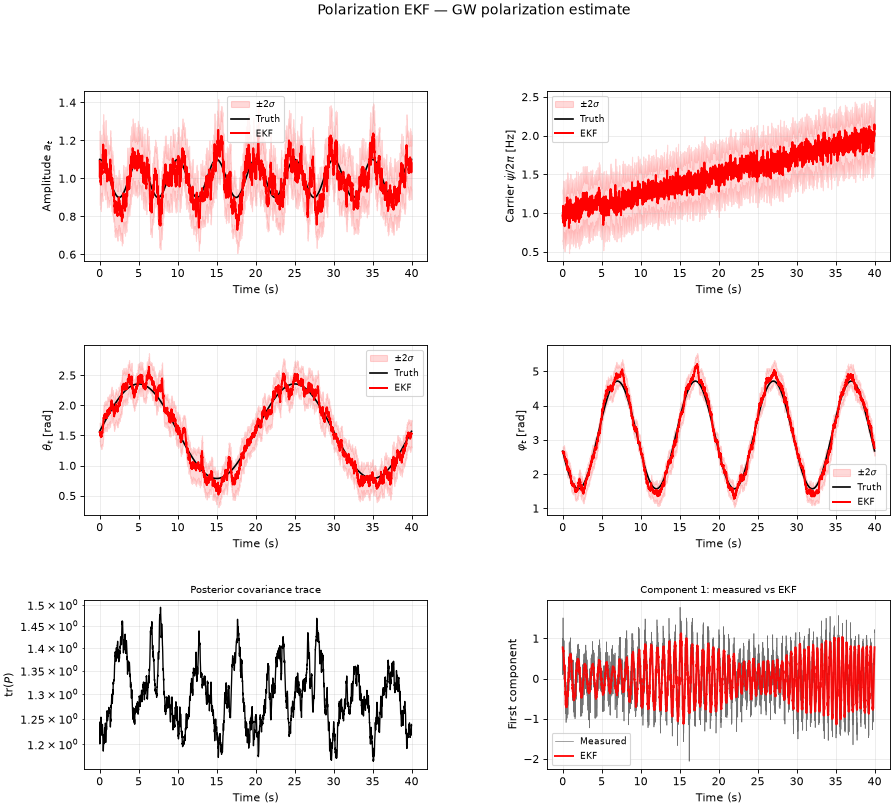

In [4]:
def steady_state_P0(sigmas, delta, dt, sigma_n):
    """Block-diagonal P0: for each (q, v_q) pair, the covariance a long run settles to (DARE)."""
    F_pair = np.array([[1.0, dt], [0.0, 1.0]])
    H_pair = np.array([[1.0, 0.0]])
    P0 = np.zeros((8, 8))
    for i, sigma in enumerate(sigmas):
        Q_pair = sigma**2 * np.array([[delta**3 / 3, delta**2 / 2], [delta**2 / 2, delta]])
        P0[2*i:2*i+2, 2*i:2*i+2] = solve_discrete_are(F_pair.T, H_pair.T, Q_pair,
                                                      np.array([[sigma_n**2]]))
    return P0

dt = 1.0 / fs
delta = 0.5                                                   # tau [s]
sigma_a, sigma_psi, sigma_theta, sigma_phi = 0.05, 0.6, 0.05, 0.05

omega_n = np.sqrt(sigma_psi**2 * delta / sigma_n**2)
print(f"PLL: omega_n = {omega_n:.2f} rad/s, lag = {alpha_chirp / omega_n**2:.3f} rad")

model = PolarizationModel(
    "GW_synth", fs=fs, delta=delta,
    sigma_a=sigma_a, sigma_psi=sigma_psi, sigma_theta=sigma_theta, sigma_phi=sigma_phi,
    sigma_n=sigma_n,
    P0=steady_state_P0([sigma_a, sigma_psi, sigma_theta, sigma_phi], delta, dt, sigma_n))

v_psi_init = 2 * np.pi * f0_chirp
model.initial_state([np.log(a_true[0]), 0.0,
                     psi_true[0] - dt * v_psi_init, v_psi_init,
                     theta_true[0], 0.0,
                     phi_true[0],   0.0])
record = model.filter(zk)

# Estimated physical parameters, reused below
xk, Pk    = record.xk, record.Pk
p_hat     = model.physical_parameters(record)
a_hat, psi_hat   = p_hat["amplitude"], p_hat["psi"]
theta_hat, phi_hat, freq_hat = p_hat["theta"], p_hat["phi"], p_hat["freq"]
freq_true = np.gradient(psi_true, 1 / fs) / (2 * np.pi)

# Amplitude, carrier frequency, theta and phi with their 2-sigma bands, tr(P), and component 1
_ = model.plot(record,
           truth=dict(amplitude=a_true, freq=freq_true, theta=theta_true, phi=phi_true),
           measured=z_noisy[:, 0])

### Dynamic Replay — Measured vs EKF (Time Slider)

Move the slider to slide a window along the signal: the first measured component against the
filter's reconstruction of it.

In [5]:
model.plot(record, interactive=True, measured=z_noisy[:, 0])

## Step 3 — Check the Covariance Trace and Spectrogram

Two checks that the filter really follows the signal:

- The **covariance trace** $\mathrm{tr}(\mathbf{P})$, the sum of the state variances, shown in the
  figure of Step 2. It stays low while the filter is locked and jumps when it loses the signal.
- The **spectrogram**, below, shows the power of the measured signal at each time and frequency.
  The chirp appears as a rising ridge, and the EKF's frequency $\hat f = v_\psi/2\pi$ should lie
  on it.

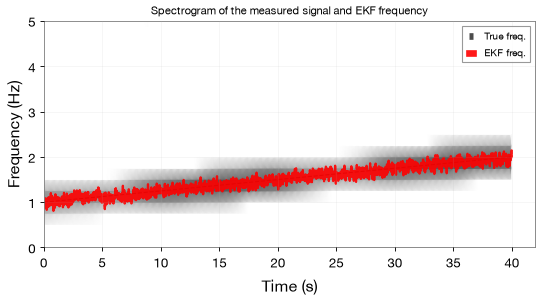

In [6]:
from gwpy.timeseries import TimeSeries

ts_synth   = TimeSeries(z_noisy[:, 0].real, sample_rate=fs, t0=0)
spec_synth = ts_synth.spectrogram2(fftlength=4.0, overlap=3.9)
t_spec = spec_synth.times.value
f_spec = spec_synth.frequencies.value
Sxx    = spec_synth.value.T

fig, ax_sp = plt.subplots(figsize=(7, 4))
ax_sp.pcolormesh(t_spec, f_spec, 10 * np.log10(Sxx + 1e-30),
                 shading='gouraud', cmap='gray_r', vmin=-20, vmax=10)
ax_sp.plot(t, freq_true, color='black', lw=1.0, ls='--', alpha=0.7, label='True freq.')
ax_sp.plot(t, freq_hat,  color='red',   lw=2.0,           alpha=0.9, label='EKF freq.')
ax_sp.set_xlabel('Time (s)')
ax_sp.set_ylabel('Frequency (Hz)')
ax_sp.set_ylim(0, 5)
ax_sp.set_title('Spectrogram of the measured signal and EKF frequency', fontsize=10)
ax_sp.legend(fontsize=9)
ax_sp.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

### Interactive Poincaré Sphere — Synthetic Signal

The polarization $(\theta, \varphi)$ as a point on the Poincaré sphere: the true path in black,
the EKF's in red. The horizontal slider sets the time, the vertical one turns the sphere.

In [7]:
model.plot_poincare(record,
                    interactive=True,
                    truth_theta=theta_true,
                    truth_phi=phi_true)

## Step 4 — Test on a Numerical GW Signal (Precessing Binary)

A harder test, shaped like the signal of a precessing binary. The orbit of the two black holes
slowly wobbles, a motion called **precession**, so the polarization angles move while the
frequency sweeps up. The signal lasts 10 s within a 20 s record. Its frequency rises from 0.5 Hz
to 5 Hz and its amplitude grows eightfold.

The frequency here rises linearly with time, which is a simplification. In a real inspiral it
grows as $(t_c - t)^{-3/8}$, where $t_c$ is the time of the merger: slowly at first, then faster
and faster, so the filter would need a still wider bandwidth near the end.

This chirp sweeps 18 times faster than the one of Step 1. The filter therefore needs a wider
bandwidth, $\tau = 0.9$ s and $\sigma_\psi = 2.0$ rad s$^{-3/2}$, and the amplitude grows quickly,
so $\sigma_a = 0.3$ s$^{-3/2}$. The cell after the plot prints the new lag.

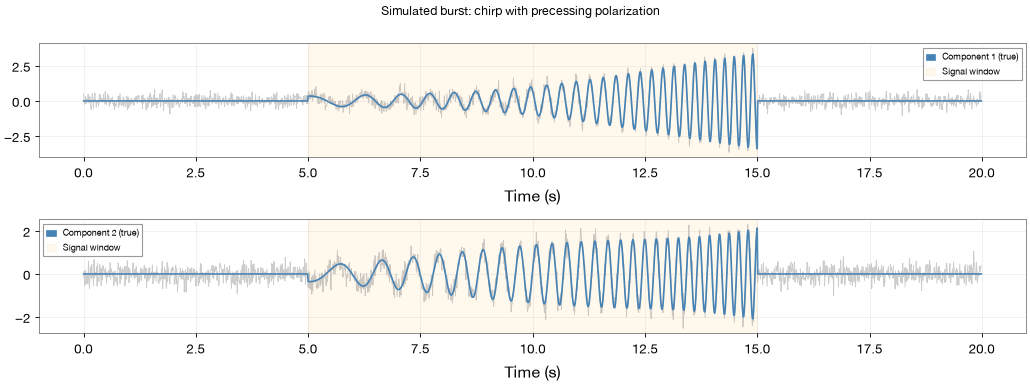

In [8]:
# Chirp with precessing polarization, inside a longer record of noise
fs_gw = 100.0
T_gw  = 20.0
t_gw  = np.arange(int(T_gw * fs_gw)) / fs_gw
N_gw  = len(t_gw)

t_start, t_end = 5.0, 15.0
window = (t_gw >= t_start) & (t_gw <= t_end)
t_sig = t_gw[window] - t_start
T_sig = t_end - t_start

f_start, f_end = 0.5, 5.0
chirp_rate = (f_end - f_start) / T_sig
psi_sig = 2 * np.pi * (f_start * t_sig + 0.5 * chirp_rate * t_sig**2)

a_sig = 0.5 * (1 + t_sig / T_sig) ** 3

theta_sig = (np.pi / 2) * (1 + 0.3 * np.sin(2 * np.pi * 0.08 * t_sig))
phi_sig   = np.pi       * (1 + 0.3 * np.sin(2 * np.pi * 0.05 * t_sig))

a_gw = np.zeros(N_gw)
a_gw[window] = a_sig
psi_gw = np.zeros(N_gw)
psi_gw[window] = psi_sig
theta_gw = np.full(N_gw, np.pi / 2)
theta_gw[window] = theta_sig
phi_gw = np.full(N_gw, np.pi)
phi_gw[window] = phi_sig

z_gw_clean = np.zeros((N_gw, 2), dtype=complex)
for k in range(N_gw):
    z_gw_clean[k] = jones_signal(a_gw[k], psi_gw[k], theta_gw[k], phi_gw[k])

sigma_n_gw = 0.3
np.random.seed(7)
noise_gw = (np.random.normal(0, sigma_n_gw, (N_gw, 2))
           + 1j * np.random.normal(0, sigma_n_gw, (N_gw, 2)))
z_gw_noisy = z_gw_clean + noise_gw

zk_gw = np.column_stack([z_gw_noisy[:, 0].real, z_gw_noisy[:, 0].imag,
                          z_gw_noisy[:, 1].real, z_gw_noisy[:, 1].imag])

fig, axes = plt.subplots(2, 1, figsize=(13, 5))
for i in range(2):
    axes[i].plot(t_gw, z_gw_noisy[:, i].real, color='gray',      alpha=0.4, lw=0.8)
    axes[i].plot(t_gw, z_gw_clean[:, i].real, color='steelblue', lw=1.5, label=f'Component {i+1} (true)')
    axes[i].axvspan(t_start, t_end, alpha=0.07, color='orange', label='Signal window')
    axes[i].set_xlabel('Time (s)')
    axes[i].legend(fontsize=8)
    axes[i].grid(True, alpha=0.3)
fig.suptitle('Simulated burst: chirp with precessing polarization', fontsize=11)
plt.tight_layout()
plt.show()

In [9]:
import matplotlib.gridspec as gridspec

zk_burst = zk_gw[window]                      # the filter runs on the 10 s burst only

dt_gw      = 1.0 / fs_gw
delta_gw   = 0.9                              # tau [s]
sigma_psi_gw, sigma_a_gw, sigma_theta_gw, sigma_phi_gw = 2.0, 0.3, 0.05, 0.05
sigmas_gw  = [sigma_a_gw, sigma_psi_gw, sigma_theta_gw, sigma_phi_gw]

omega_n_gw = np.sqrt(sigma_psi_gw**2 * delta_gw / sigma_n_gw**2)
alpha_gw   = 2 * np.pi * (f_end - f_start) / T_sig
print(f"Chirp: {f_start} -> {f_end} Hz in {T_sig:.0f} s | d2psi/dt2 = {alpha_gw:.3f} rad/s^2")
print(f"PLL: omega_n = {omega_n_gw:.2f} rad/s, lag = {alpha_gw / omega_n_gw**2:.3f} rad")

model_gw = PolarizationModel(
    'GW_inspiral', fs=fs_gw, delta=delta_gw,
    sigma_a=sigma_a_gw, sigma_psi=sigma_psi_gw,
    sigma_theta=sigma_theta_gw, sigma_phi=sigma_phi_gw,
    sigma_n=sigma_n_gw, P0=steady_state_P0(sigmas_gw, delta_gw, dt_gw, sigma_n_gw))

v_psi_gw_init = 2 * np.pi * f_start
model_gw.initial_state([np.log(a_sig[0]),           0.0,
                         -dt_gw * v_psi_gw_init,    v_psi_gw_init,
                         theta_sig[0],               0.0,
                         phi_sig[0],                 0.0])

record_gw = model_gw.filter(zk_burst)

xk_gw   = record_gw.xk
Pk_gw   = record_gw.Pk
sig2_gw = 2.0 * np.sqrt(np.diagonal(Pk_gw, axis1=1, axis2=2))

a_hat_gw     = np.exp(xk_gw[:, 0])
psi_hat_gw   = xk_gw[:, 2]
theta_hat_gw = xk_gw[:, 4]
phi_hat_gw   = xk_gw[:, 6]
freq_hat_gw  = xk_gw[:, 3] / (2 * np.pi)
freq_true_burst = f_start + chirp_rate * t_sig

sig2_a_gw  = a_hat_gw * sig2_gw[:, 0]
trace_P_gw = np.trace(Pk_gw, axis1=1, axis2=2)
z1_hat_gw  = a_hat_gw * np.exp(1j * psi_hat_gw) * np.cos(theta_hat_gw / 2)

Chirp: 0.5 -> 5.0 Hz in 10 s | d2psi/dt2 = 2.827 rad/s^2
PLL: omega_n = 6.32 rad/s, lag = 0.071 rad


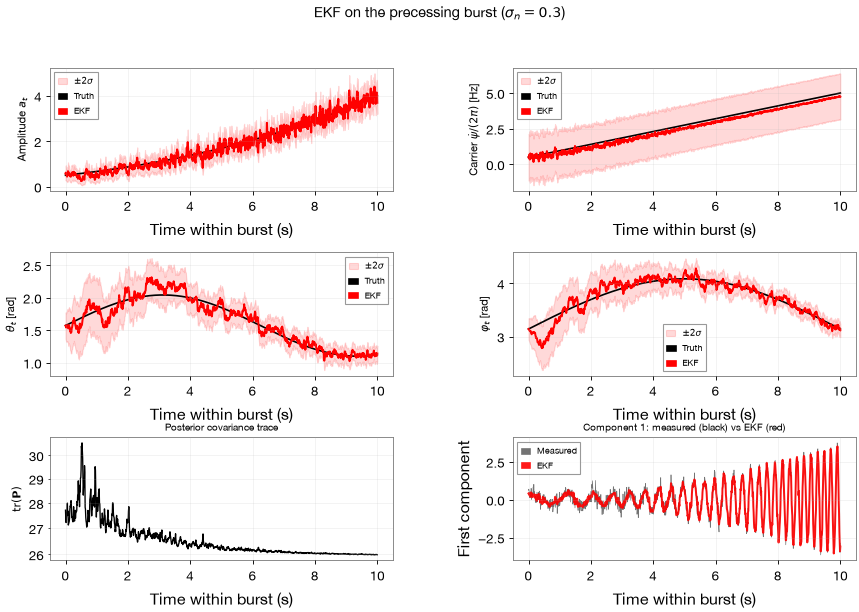

In [10]:
fig1 = plt.figure(figsize=(13, 8))
gs   = gridspec.GridSpec(3, 2, figure=fig1, hspace=0.50, wspace=0.35)

params_gw = [
    (a_hat_gw,     a_sig,           sig2_a_gw,               r'Amplitude $a_t$'),
    (freq_hat_gw,  freq_true_burst, sig2_gw[:, 3]/(2*np.pi), r'Carrier $\dot{\psi}/(2\pi)$ [Hz]'),
    (theta_hat_gw, theta_sig,       sig2_gw[:, 4],           r'$\theta_t$ [rad]'),
    (phi_hat_gw,   phi_sig,         sig2_gw[:, 6],           r'$\varphi_t$ [rad]'),
]

for idx, (hat, true, s2, ylabel) in enumerate(params_gw):
    ax = fig1.add_subplot(gs[idx // 2, idx % 2])
    ax.fill_between(t_sig, hat - s2, hat + s2, alpha=0.15, color='red', label=r'$\pm 2\sigma$')
    ax.plot(t_sig, true, color='black', lw=1.5, label='Truth')
    ax.plot(t_sig, hat,  color='red',   lw=1.8, label='EKF')
    ax.set_xlabel('Time within burst (s)')
    ax.set_ylabel(ylabel, fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.25)

ax_cov = fig1.add_subplot(gs[2, 0])
ax_cov.semilogy(t_sig, trace_P_gw, color='black', lw=1.2)
ax_cov.set_xlabel('Time within burst (s)')
ax_cov.set_ylabel(r'$\mathrm{tr}(\mathbf{P})$', fontsize=10)
ax_cov.set_title('Posterior covariance trace', fontsize=9)
ax_cov.grid(True, alpha=0.25, which='both')

ax_sig = fig1.add_subplot(gs[2, 1])
ax_sig.plot(t_sig, zk_burst[:, 0], color='black', lw=0.6, alpha=0.55, label='Measured')
ax_sig.plot(t_sig, z1_hat_gw.real, color='red',   lw=1.8, alpha=0.90, label='EKF')
ax_sig.set_xlabel('Time within burst (s)')
ax_sig.set_ylabel('First component')
ax_sig.set_title('Component 1: measured (black) vs EKF (red)', fontsize=9)
ax_sig.legend(fontsize=8)
ax_sig.grid(True, alpha=0.25)

fig1.suptitle(r'EKF on the precessing burst ($\sigma_n = 0.3$)', fontsize=13)
plt.show()

### Interactive Poincaré Sphere — GW Inspiral Burst

The same sphere for the burst: the precession draws a path, which the filter follows.

In [11]:
model_gw.plot_poincare(record_gw,
                        interactive=True,
                        truth_theta=theta_sig,
                        truth_phi=phi_sig)

## Step 5 — Test the Effect of Real Interferometer Noise (Colored Noise)

Real detector noise is not white: its power depends on the frequency. It is strongest at low
frequency, from ground motion, and it has narrow **lines** at fixed frequencies, from the mirror
suspensions and the power grid. We imitate it with white noise passed through a 0.3 Hz low-pass
filter, plus two lines at 1.2 Hz and 7.6 Hz. Then we clean the data as the paper does:

1. a high-pass filter at 0.4 Hz, just below the start of the chirp, against the low-frequency
   noise,
2. two narrow **notch** filters that cut out the lines,
3. a low-pass filter at 10 Hz, above the signal.

The 1.2 Hz notch also cuts a slice out of the signal, since the chirp crosses 1.2 Hz. The point
of this test (Section 4.3 of the paper) is that the EKF keeps tracking the frequency across that
gap, because its model assumes the frequency changes smoothly. The high-pass filter matters
more: with a cut at 0.02 Hz instead, the low-frequency noise stays stronger than the young, weak
chirp, and the filter follows the noise for the first 5 s.

The filters work on the real part of the data. The EKF needs the complex signal back, which the
Hilbert transform provides: it builds the **analytic signal**, the complex signal whose real part
is the filtered data.

In [12]:
from scipy.signal import butter, sosfilt, iirnotch, sosfiltfilt, tf2sos, hilbert

np.random.seed(99)
f_lines = [1.2, 7.6]        # frequencies of the two noise lines [Hz]

# Low-frequency noise: white noise through a 0.3 Hz low-pass filter, 3 times sigma_n in size
white = np.random.normal(0, 1.0, (N_gw, 2)) + 1j * np.random.normal(0, 1.0, (N_gw, 2))
colored = sosfilt(butter(2, 0.3, btype='low', fs=fs_gw, output='sos'), white, axis=0)
colored = colored / np.std(colored) * sigma_n_gw * 3
# Two lines of amplitude 0.5 with random phases
for f_line in f_lines:
    colored += 0.5 * np.exp(1j * (2 * np.pi * f_line * t_gw[:, None]
                                  + np.random.uniform(0, 2 * np.pi, 2)))

z_gw_colored = z_gw_clean + colored

def apply_filters(sig_2d, fs):
    """High-pass at 0.4 Hz, notches at f_lines, low-pass at 10 Hz."""
    out = np.zeros_like(sig_2d)
    for col in range(sig_2d.shape[1]):
        s = sig_2d[:, col]
        s = sosfiltfilt(butter(2, 0.4, btype='high', fs=fs, output='sos'), s)
        for f_line in f_lines:
            b, a_c = iirnotch(f_line, Q=30, fs=fs)      # quality factor Q_f = 30
            s = sosfiltfilt(tf2sos(b, a_c), s)
        s = sosfiltfilt(butter(4, 10.0, btype='low', fs=fs, output='sos'), s)
        out[:, col] = s
    return out

z_real     = np.column_stack([z_gw_colored[:, 0].real, z_gw_colored[:, 1].real])
z_filtered = apply_filters(z_real, fs_gw)

z_analytic = hilbert(z_filtered, axis=0)        # complex signal whose real part is z_filtered

zk_col_full  = np.column_stack([z_analytic[:, 0].real, z_analytic[:, 0].imag,
                                 z_analytic[:, 1].real, z_analytic[:, 1].imag])
zk_col_burst = zk_col_full[window]

In [13]:
# Same filter settings as in Step 4
model_col = PolarizationModel(
    'GW_colored', fs=fs_gw, delta=delta_gw,
    sigma_a=sigma_a_gw, sigma_psi=sigma_psi_gw,
    sigma_theta=sigma_theta_gw, sigma_phi=sigma_phi_gw,
    sigma_n=sigma_n_gw, P0=steady_state_P0(sigmas_gw, delta_gw, dt_gw, sigma_n_gw))

v_psi_col_init = 2 * np.pi * f_start
model_col.initial_state([np.log(a_sig[0]),           0.0,
                          -dt_gw * v_psi_col_init,   v_psi_col_init,
                          theta_sig[0],               0.0,
                          phi_sig[0],                 0.0])

record_col = model_col.filter(zk_col_burst)

xk_col   = record_col.xk
freq_col = xk_col[:, 3] / (2 * np.pi)
a_col    = np.exp(xk_col[:, 0])

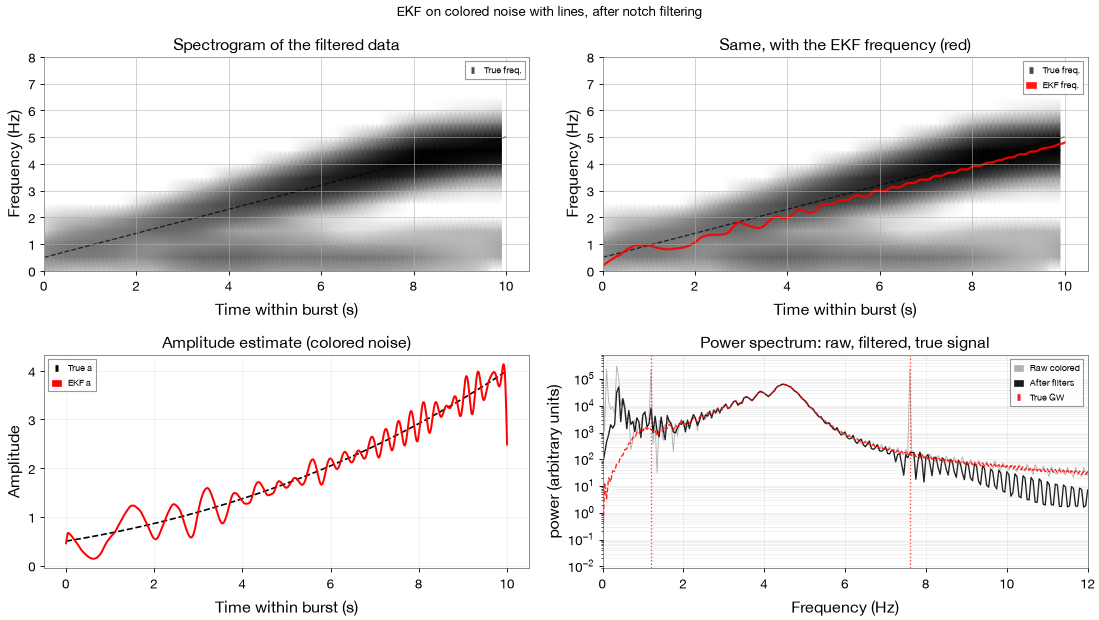

In [14]:
ts_filt    = TimeSeries(z_filtered[window, 0], sample_rate=fs_gw, t0=0)
spec_filt  = ts_filt.spectrogram2(fftlength=2.0, overlap=1.9)
t_filt_sp  = spec_filt.times.value
f_filt_sp  = spec_filt.frequencies.value
Sxx_filt   = spec_filt.value.T

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].pcolormesh(t_filt_sp, f_filt_sp, 10*np.log10(Sxx_filt + 1e-30),
                       shading='gouraud', cmap='gray_r', vmin=-30, vmax=5)
axes[0, 0].plot(t_sig, freq_true_burst, '--', color='black', lw=1.2, alpha=0.7, label='True freq.')
axes[0, 0].set_ylim(0, 8)
axes[0, 0].set_xlabel('Time within burst (s)')
axes[0, 0].set_ylabel('Frequency (Hz)')
axes[0, 0].set_title('Spectrogram of the filtered data')
axes[0, 0].legend(fontsize=8)

axes[0, 1].pcolormesh(t_filt_sp, f_filt_sp, 10*np.log10(Sxx_filt + 1e-30),
                       shading='gouraud', cmap='gray_r', vmin=-30, vmax=5)
axes[0, 1].plot(t_sig, freq_true_burst, '--', color='black', lw=1.2, alpha=0.7, label='True freq.')
axes[0, 1].plot(t_sig, freq_col,             color='red',   lw=2.0, alpha=0.9, label='EKF freq.')
axes[0, 1].set_ylim(0, 8)
axes[0, 1].set_xlabel('Time within burst (s)')
axes[0, 1].set_ylabel('Frequency (Hz)')
axes[0, 1].set_title('Same, with the EKF frequency (red)')
axes[0, 1].legend(fontsize=8)

axes[1, 0].plot(t_sig, a_sig,  color='black', lw=1.5, ls='--', label='True a')
axes[1, 0].plot(t_sig, a_col,  color='red',   lw=1.8, label='EKF a')
axes[1, 0].set_xlabel('Time within burst (s)')
axes[1, 0].set_ylabel('Amplitude')
axes[1, 0].set_title('Amplitude estimate (colored noise)')
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(True, alpha=0.25)

from numpy.fft import rfft, rfftfreq
freqs_psd = rfftfreq(N_gw, 1/fs_gw)
S_col_raw  = np.abs(rfft(z_real[:, 0]))**2
S_col_filt = np.abs(rfft(z_filtered[:, 0]))**2
S_clean_gw = np.abs(rfft(z_gw_clean[:, 0].real))**2
axes[1, 1].semilogy(freqs_psd, S_col_raw,  color='gray',   alpha=0.6, lw=0.8, label='Raw colored')
axes[1, 1].semilogy(freqs_psd, S_col_filt, color='black',  alpha=0.9, lw=1.2, label='After filters')
axes[1, 1].semilogy(freqs_psd, S_clean_gw, color='red',    alpha=0.9, lw=1.2, ls='--', label='True GW')
for f_line in f_lines:
    axes[1, 1].axvline(f_line, ls=':', color='red', lw=1.2, alpha=0.8)
axes[1, 1].set_xlim(0, 12)
axes[1, 1].set_xlabel('Frequency (Hz)')
axes[1, 1].set_ylabel('power (arbitrary units)')
axes[1, 1].set_title('Power spectrum: raw, filtered, true signal')
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(True, alpha=0.3, which='both')

fig.suptitle('EKF on colored noise with lines, after notch filtering', fontsize=12)
plt.tight_layout()
plt.show()

## Possible Improvements and Extensions

- **Smoothing.** For a recorded event, `model.filter(zk, smooth=True)` adds the
  Rauch–Tung–Striebel (RTS) backward pass, which also uses later samples and lowers the variance.
- **Whitening.** Real pipelines divide the data by the noise amplitude spectrum, measured away from
  the signal, so that the noise becomes white, as the Kalman filter assumes.
- **Unscented filter.** At low SNR the linearization of $h$ can be poor. `UnscentedKalmanFilter`
  passes sample points through $h$ itself instead of using its Jacobian.
- **Bounded angles.** $\theta$ and $\varphi$ are bounded, but the constant-velocity model lets them
  drift without limit. A model that pulls them back, $\dot q = -\kappa q + w$ (an
  Ornstein–Uhlenbeck process), would prevent this.
- **Poles of the sphere.** At $\theta = 0$ or $\pi$ the angle $\varphi$ is undefined and the EKF's
  linearization fails there. Coordinates without this singularity would remove the problem.